[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%9B%B4%E6%8E%A5%E4%BD%BF%E7%94%A8pandas%E7%B9%AA%E5%88%B6%E5%9C%96%E8%A1%A8/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E8%8C%B6%E8%AA%9E%E6%99%82%E5%85%89_%E4%B8%80%E8%A1%8C%E7%95%AB%E5%87%BA%E5%B9%B4%E5%BA%A6%E7%B0%A1%E5%A0%B1%E5%9C%96.ipynb)

# 🖼️ 茶語時光：一行程式畫出年度簡報圖

> 🧋 **情境**：尾牙前要做年度簡報。上一章你學會用 groupby 算出各種統計，這次老闆要的是「圖」：全年營收走勢、颱風和演唱會的影響、不同時段客人點什麼、會員是不是比較會花錢。好消息是——**表格整理好之後，pandas 一行就能畫圖**。

| 素材檔案 | 內容 |
| --- | --- |
| `每日營收_2024.csv` | 2024 年每天 × 5 家門市的杯數、營收、最高溫與特殊事件（颱風、演唱會、節日、活動） |
| `訂單明細_2024-07.csv` | 7 月份的訂單明細（約 4 萬筆） |

> ⚠️ 「茶語時光」是課程虛構的品牌，資料為模擬資料；節日與颱風假的日期參考台灣實際情況，方便你對照生活經驗。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '每日營收_2024.csv',
    '訂單明細_2024-07.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%9B%B4%E6%8E%A5%E4%BD%BF%E7%94%A8pandas%E7%B9%AA%E5%88%B6%E5%9C%96%E8%A1%A8/%E7%9B%B4%E6%8E%A5%E4%BD%BF%E7%94%A8pandas%E7%B9%AA%E5%88%B6%E5%9C%96%E8%A1%A8_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['每日營收_2024.csv', '訂單明細_2024-07.csv']


In [2]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

/private/tmp/claude-501/-Users-roberthsu2003-Documents-GitHub-PythonForDataAnalysis/a2ce4768-05fa-40ab-bf51-d29fa66026ee/scratchpad/venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


## 圖 1：全年營收走勢——pivot 之後一行 `.plot()`

**白話說明**：把資料整理成「日期 × 門市」的寬表，`.plot()` 會自動把**索引當 X 軸、每一欄畫成一條線**。每日數字太亂，再加上 7 日移動平均讓趨勢更清楚。

門市,台中逢甲店,台北信義店,台北西門店,台南成大店,高雄巨蛋店
日期,,,,,
2024-01-01,18865,14748,12170,16298,16568
2024-01-02,18323,15745,14060,15772,17456
2024-01-03,19894,17585,15859,20623,15936


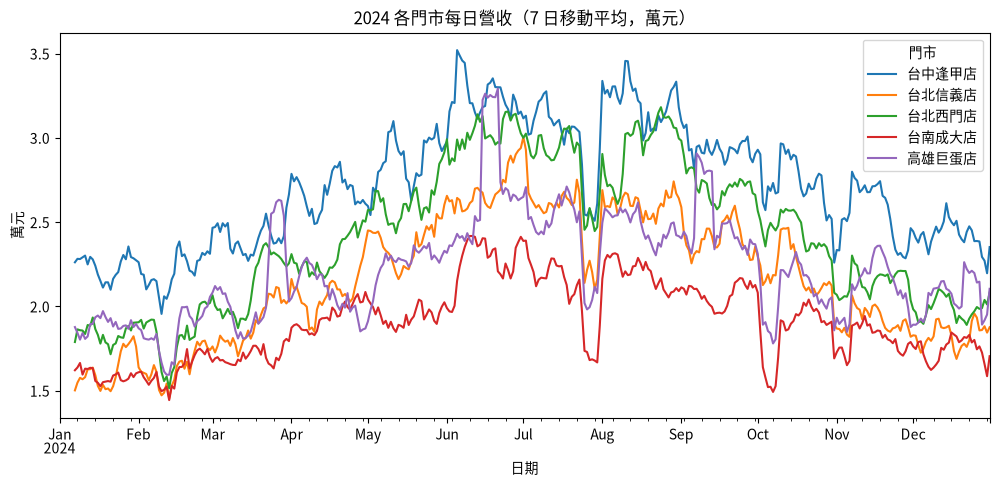

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_csv('每日營收_2024.csv', parse_dates=['日期'])
wide = daily.pivot(index='日期', columns='門市', values='營收')        # 日期 × 門市 的寬表
display(wide.head(3))

ax = (wide.rolling(7).mean() / 10000).plot(figsize=(12, 5), title='2024 各門市每日營收（7 日移動平均，萬元）')   # 一行畫 5 條線
ax.set_ylabel('萬元')
plt.show()

## 圖 2：把颱風、演唱會標在圖上——讓圖會說故事

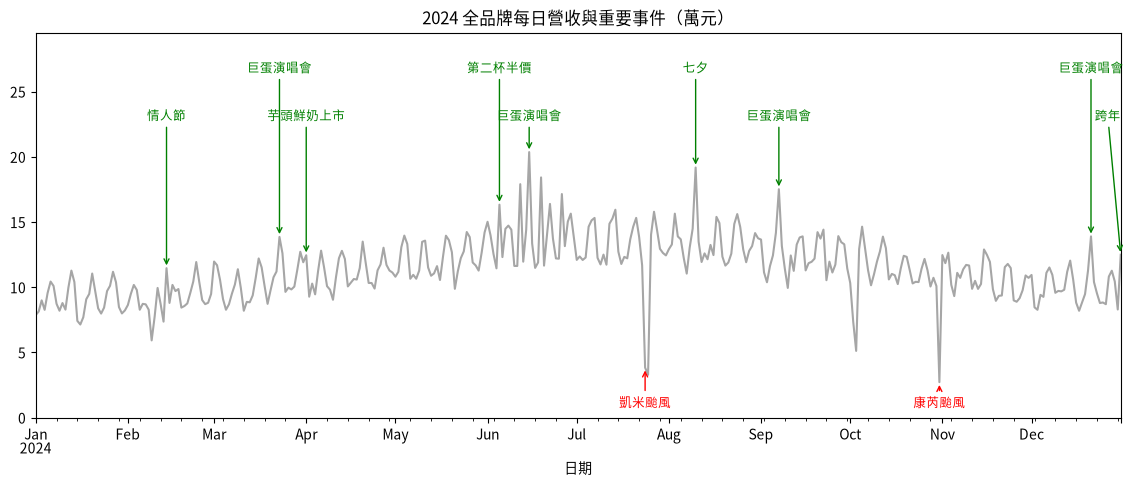

In [4]:
total = daily.groupby('日期')['營收'].sum() / 10000                     # 全品牌每日營收（萬元）
events = daily[daily['事件'].notna()].groupby('日期')['事件'].first()    # 有特殊事件的日子

ax = total.plot(figsize=(14, 5), color='gray', alpha=0.7, title='2024 全品牌每日營收與重要事件（萬元）')
ax.set_ylim(0, total.max() * 1.45)                                     # 上方留空間放標註文字

last_seen, k = {}, 0
for date, name in events.items():
    if name not in ('凱米颱風', '康芮颱風', '巨蛋演唱會', '情人節', '七夕', '第二杯半價', '芋頭鮮奶上市', '跨年'):
        continue
    if name in last_seen and (date - last_seen[name]).days < 30:      # 一個月內的同一事件只標第一次
        continue
    last_seen[name] = date
    y = total[date]
    if '颱風' in name:                                                  # 颱風：紅色，文字放在下方
        ax.annotate(name, xy=(date, y), xytext=(date, 0.8), ha='center', fontsize=9, color='red',
                    arrowprops=dict(arrowstyle='->', color='red'))
    else:                                                               # 好事件：綠色，文字高低交錯避免重疊
        k += 1
        ax.annotate(name, xy=(date, y), xytext=(date, total.max() * (1.12 if k % 2 else 1.3)),
                    ha='right' if date.month == 12 and date.day > 25 else 'center',   # 年底的標籤靠右，避免超出圖框
                    fontsize=9, color='green', arrowprops=dict(arrowstyle='->', color='green'))
plt.show()

> 💡 **看懂結果**：凱米、康芮颱風那幾天營收直接腰斬；情人節、七夕、跨年、巨蛋演唱會則是明顯的高峰。6 月每週三的「第二杯半價」讓週三變成一週最好的一天。**把事件標上去，老闆一看就懂「為什麼那天特別高或特別低」。**
>
> 🤖 **換你問 AI**：「請畫出全品牌每日營收折線圖，並在『事件』欄位有值的日期加上箭頭標註，颱風用紅色、節日活動用綠色。」

## 圖 3：不同時段，客人點什麼？——百分比堆疊長條圖

類別,冰沙,奶茶,果茶,純茶,鮮奶
時段,,,,,
午餐前後,13.2,16.0,21.0,10.7,39.0
下午茶,13.7,24.8,22.5,10.7,28.3
晚上,12.8,16.3,30.1,13.2,27.6


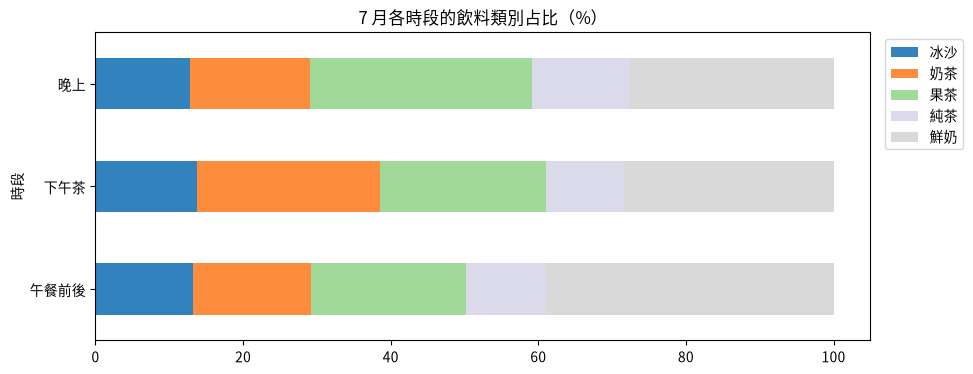

In [5]:
orders = pd.read_csv('訂單明細_2024-07.csv', parse_dates=['訂單時間'])
orders['時段'] = pd.cut(orders['訂單時間'].dt.hour, bins=[9, 13, 17, 23], labels=['午餐前後', '下午茶', '晚上'])
mix = pd.crosstab(orders['時段'], orders['類別'], values=orders['數量'], aggfunc='sum', normalize='index') * 100   # 每個時段各類別占比
display(mix.round(1))

ax = mix.plot.barh(stacked=True, figsize=(10, 4), colormap='tab20c', title='7 月各時段的飲料類別占比（%）')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')                  # 圖例放到右邊
plt.show()

> 💡 **看懂結果**：午餐前後鮮奶系列最受歡迎（很多人拿它當正餐），下午茶時段奶茶比例上升，晚上則是清爽的果茶、純茶比較多。**看板與推播訊息可以依時段換主打。**

## 圖 4：會員真的比較會花錢嗎？——seaborn 統計長條圖

**白話說明**：seaborn 畫平均值長條圖時，會自動加上**誤差線（信賴區間）**，告訴你這個平均有多可靠。

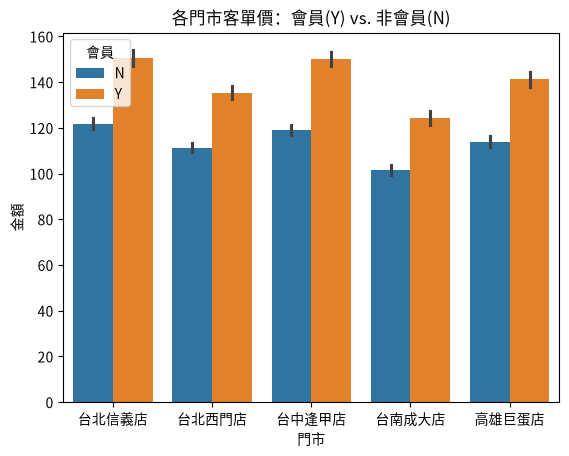

In [6]:
import seaborn as sns

per_order = orders.groupby(['訂單編號', '門市', '會員'], as_index=False)['金額'].sum()   # 先算每筆訂單金額
ax = sns.barplot(data=per_order, x='門市', y='金額', hue='會員', errorbar=('ci', 95))
ax.set_title('各門市客單價：會員(Y) vs. 非會員(N)')
plt.show()

> 💡 **看懂結果**：每家店的會員客單價都比較高，而且誤差線沒有重疊——差異是穩定的，不是碰巧。

## 圖 5：訂單金額的分布——直方圖與盒鬚圖

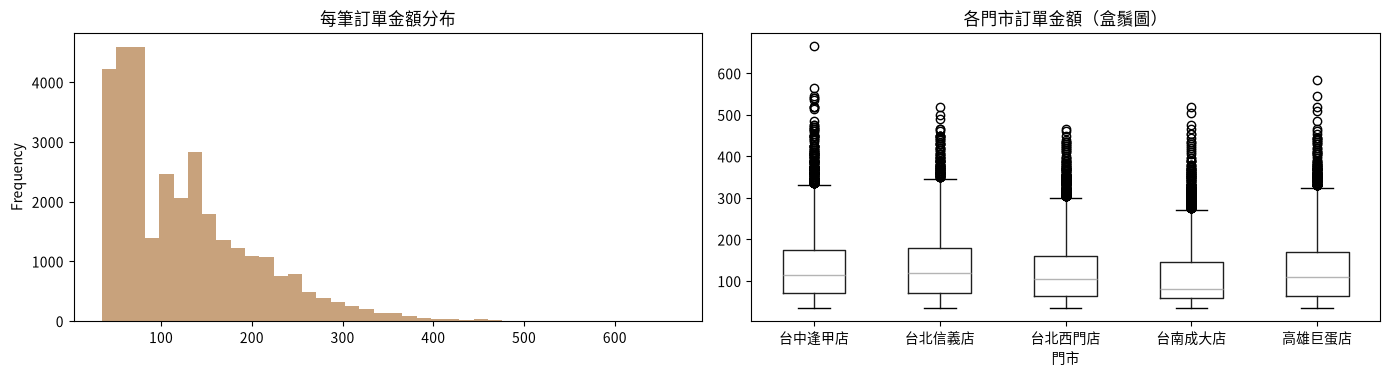

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_order['金額'].plot.hist(bins=40, ax=axes[0], color='#C8A27C', title='每筆訂單金額分布')
per_order.boxplot(column='金額', by='門市', ax=axes[1], grid=False)      # 盒鬚圖：中間的線是中位數，點是極端值
axes[1].set_title('各門市訂單金額（盒鬚圖）')
fig.suptitle('')
plt.tight_layout()
plt.savefig('訂單金額分布.png', dpi=200, bbox_inches='tight')           # 存成簡報用的圖檔
plt.show()

> 💡 **看懂結果**：大部分訂單都是 1～2 杯（100 元左右），但有一條長長的「尾巴」——少數大額團購訂單。平均值會被這些大單拉高，所以報告「典型客人花多少」時，**中位數比平均數更貼近事實**。

---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [8]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：台南成大店：杯數和氣溫畫在同一張圖（雙 Y 軸）

<details><summary>💡 卡住了？點我看提示</summary>

`ax2 = ax.twinx()` 會建立一個共用 X 軸、右邊有自己 Y 軸的新座標；第二條線畫在 `ax=ax2` 上。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
tn = daily[daily['門市'] == ___].set_index('日期')
ax = tn['杯數'].plot(figsize=(12, 4), color='#8B5E3C', label='杯數')
ax2 = ax.___()                                     # 共用 X 軸、右邊另一個 Y 軸
tn['最高溫'].plot(ax=ax2, color='orange', alpha=0.6, label='最高溫')
ax.set_title('台南成大店：每日杯數與最高溫')
plt.show()

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
tn = daily[daily['門市'] == '台南成大店'].set_index('日期')
ax = tn['杯數'].plot(figsize=(12, 4), color='#8B5E3C', label='杯數')
ax2 = ax.twinx()
tn['最高溫'].plot(ax=ax2, color='orange', alpha=0.6, label='最高溫')
ax.set_title('台南成大店：每日杯數與最高溫')
plt.show()
```

</details>

### ✍️ 練習 2：各門市的甜度占比，畫成百分比堆疊長條圖

<details><summary>💡 卡住了？點我看提示</summary>

`pd.crosstab(列, 欄, normalize='index')` 先算出占比表；`.plot.barh(stacked=True)` 一行畫出堆疊長條。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
sweet = pd.crosstab(orders['門市'], orders[___], normalize='index')[['正常糖', '少糖', '半糖', '微糖', '無糖']] * 100
sweet.plot.barh(stacked=___, figsize=(10, 4), colormap='copper', title='各門市甜度占比（%）')
plt.show()

In [ ]:
# @title ✅ 執行這格，檢查練習 2
check('sweet', pd.crosstab(orders['門市'], orders['甜度'], normalize='index')[['正常糖', '少糖', '半糖', '微糖', '無糖']] * 100)

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
sweet = pd.crosstab(orders['門市'], orders['甜度'], normalize='index')[['正常糖', '少糖', '半糖', '微糖', '無糖']] * 100
sweet.plot.barh(stacked=True, figsize=(10, 4), colormap='copper', title='各門市甜度占比（%）')
plt.show()
```

</details>

### ✍️ 練習 3：會員 vs. 非會員：訂單金額的分布長得一樣嗎？

<details><summary>💡 卡住了？點我看提示</summary>

`sns.histplot(data=表格, x=欄位, hue=分組欄位)` 會用不同顏色畫出每一組的分布。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
sns.histplot(data=per_order, x='金額', hue=___, bins=40, element='step')
plt.title('會員 vs. 非會員訂單金額分布')
plt.show()

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
sns.histplot(data=per_order, x='金額', hue='會員', bins=40, element='step')
plt.title('會員 vs. 非會員訂單金額分布')
plt.show()
```

</details>